# Wavefield · Irregular free-surface topography

SWEEP solves the free-surface topography problem with **two
discretisation families**, both driven through the propagator's
``topography=`` keyword.  When ``topography`` is given a free surface is
implicit; *which* scheme runs is chosen by the equation class plus an
optional ``topo_method=`` switch:

| Family | Equation | How to select | Reference |
|---|---|---|---|
| **Image / staircase** | `Acoustic` | `topography=` (only option) | Mittet 2002 |
| **Image (stress mirror)** | `Elastic` | `topography=` | Robertsson 1996 |
| **Curvilinear** (boundary-fitted) | `AcousticCurvilinear` / `ElasticCurvilinear` | dedicated class + `topography=` | Bartana et al. 2026 (elastic) |

So acoustic and elastic each support **2 methods** (image,
curvilinear).  This notebook runs them all on
one Gaussian-hill model and compares **wavefields and shot records**,
grouped by physics:

* **Acoustic group** — image vs. curvilinear, compared on *pressure*.
* **Elastic group** — image vs. curvilinear, compared on *|v|*.

!!! note "Curvilinear coordinates"
    The image method works on the **physical grid**: the surface
    is a staircase of row indices.  The curvilinear method instead maps
    the irregular surface onto the **flat top row η = 0 of a
    boundary-fitted (ξ, η) grid** — but it is driven and read the same
    way: sources/receivers are physical grid indices that the propagator
    places on its rows, and its snapshots come back on the physical
    (X, Z) grid.
    Curvilinear runs on the eager backend only (`impl='eager'`).
    `ElasticCurvilinear` is a **collocated, conservative** scheme with
    asymmetric operators and a rotated traction-free surface (Bartana,
    Xu & Rickett) — section 3b; `AcousticCurvilinear` is the plain
    chain-rule staggered scheme.

``topography=`` takes a 1-D array of surface row indices per
column. Only single-valued surfaces are supported: overhangs and caves
cannot be expressed, and a 2-D array is rejected with a ``ValueError``.
The image method needs whole rows; the curvilinear classes also take
fractional ones.

## 1. Build the model

A 192 × 256 grid, ``dh=5 m``. A single Gaussian hill, 50 m (10 cells)
high above a flat baseline at row 24 of the physical grid.  Sources and
receivers are physical grid indices for every method: the image runs
round them to whole rows (`sources` / `receivers`), the curvilinear runs
take the exact depth below the fractional surface (`sources_curv` /
`receivers_curv`) and map it onto their own rows.

device: cuda


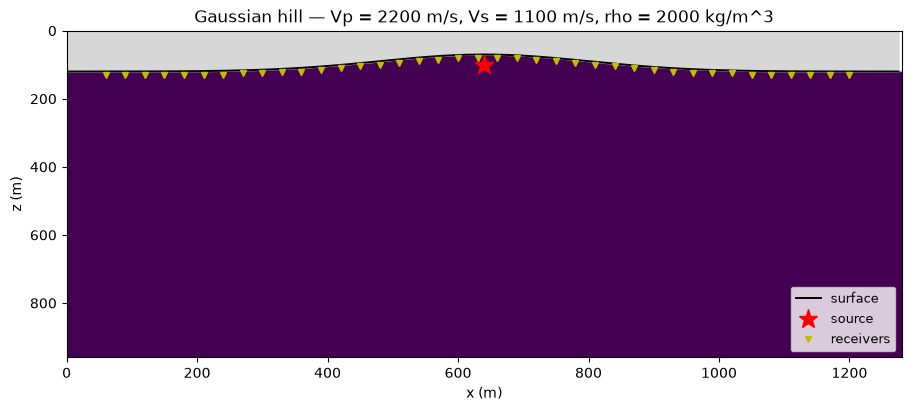

topo range: rows 14..24 (depths 70..120 m)
Rayleigh wavelength 126 m = 25.3 cells; record 1.20 s
air cells (rows above surface): 5346 of 49152


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations import (
    Acoustic, Elastic,
    AcousticCurvilinear, ElasticCurvilinear,  # boundary-fitted (eager-only)
)
from sweep.propagator.torch import PropTorch
from sweep.signal import ricker

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# eager on CUDA would run its stencil convolutions in TF32 (~1e-4 off): keep FP32
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
print('device:', device)

# Grid — 1.28 km x 0.96 km of half-space, sampled at 5 m
NZ, NX = 192, 256
DH     = 5.0
DT     = 5.0e-4
NT     = 2400             # 1.20 s; the far-offset Rayleigh arrives at 0.75 s
ABCN   = 60               # 300 m of PML, as before
SO     = 4                # same order for all four runs, so the comparison is fair
FREQ, DELAY = 8.0, 0.18
# The Rayleigh wave runs at vR = 0.9194*Vs = 1011 m/s, so at 8 Hz its wavelength
# is 126 m = 25.3 cells here.  The image method is usable from ~10 points per
# wavelength (Kristek et al. 2002), but the collocated curvilinear scheme wants
# two to three times that before its free-surface closure stops leaving a visible
# coda -- so the grid is set by the stricter of the two methods, not the
# looser.  The record is long enough for the surface wave to reach the far
# receivers; cutting it earlier hides the event the free surface exists for.

# Bulk models — homogeneous half-space
VP, VS, RHO = 2200.0, 1100.0, 2000.0
vp  = torch.full((NZ, NX), VP).to(device)
vs  = torch.full((NZ, NX), VS).to(device)
rho = torch.full((NZ, NX), RHO).to(device)

# Topography — a single Gaussian hill, 50 m high, sigma = 160 m
x = np.arange(NX, dtype=np.float32)
hill_h0   = 50.0 / DH
hill_x0   = NX / 2
hill_sig  = 160.0 / DH
hill_base = 120.0 / DH
topo_frac = hill_base - hill_h0 * np.exp(-((x - hill_x0) ** 2) / (2.0 * hill_sig ** 2))
# The image method needs whole rows (the surface is a staircase of cell faces);
# the curvilinear methods take the fractional surface directly, and rounding
# it would turn the hill into a staircase that radiates grid-scale energy
# along the free surface.
topo_row  = topo_frac.round().astype(np.int64)

# --- Physical-grid geometry (image method) ---------------------------------
# Source 3 cells below the local surface, receivers 1 cell below it; the
# z-index is the TRUE physical row, so it tracks the hill.
SRC_M, REC_M = 30.0, 10.0          # depths below the local surface, in metres
DEPTH_SRC = int(round(SRC_M / DH))   # physical grid (image)
DEPTH_REC = int(round(REC_M / DH))
src_x = NX // 2
src_z = int(topo_row[src_x]) + DEPTH_SRC
sources = torch.from_numpy(np.array([[src_x, src_z]], dtype=np.int64)).to(device)
rec_step = int(round(30.0 / DH))   # a receiver every 30 m
rec_edge = int(round(60.0 / DH))
rec_x = np.arange(rec_edge, NX - rec_edge, rec_step, dtype=np.int64)
rec_z = (topo_row[rec_x] + DEPTH_REC).astype(np.int64)
receivers = torch.from_numpy(np.stack([rec_x, rec_z], axis=-1)[None, ...]).to(device)

# --- Curvilinear geometry: the same depths below the TRUE surface ----------
# Sources and receivers are physical grid indices for every method, and the
# curvilinear propagator maps them onto its boundary-fitted rows itself (one of
# those rows is D(x)/(NZ-1) metres, not DH).  Its surface is fractional, so the
# depths can be exact here, where the image method has to round to whole rows.
sources_curv = torch.tensor([[src_x, topo_frac[src_x] + SRC_M / DH]],
                            dtype=torch.float64).to(device)
receivers_curv = torch.from_numpy(
    np.stack([rec_x, topo_frac[rec_x] + REC_M / DH], axis=-1)[None, ...]).to(device)

# Ricker wavelet
t = np.arange(NT, dtype=np.float32) * DT - DELAY
wavelet = torch.tensor((1.0e3 * ricker(t, f=FREQ)).astype(np.float32)).to(device)


# QC the model
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.imshow(np.where(np.arange(NZ)[:, None] < topo_row[None, :], np.nan, VP), cmap='viridis',
          extent=[0, NX * DH, NZ * DH, 0], aspect='auto')
ax.plot(np.arange(NX) * DH, topo_frac * DH, 'k-', lw=1.4, label='surface')
ax.fill_between(np.arange(NX) * DH, 0, topo_frac * DH, color='lightgray', alpha=0.9)
ax.plot(src_x * DH, src_z * DH, 'r*', ms=14, label='source')
ax.plot(rec_x * DH, rec_z * DH, 'yv', ms=4, label='receivers')
ax.set_xlabel('x (m)'); ax.set_ylabel('z (m)')
ax.set_title('Gaussian hill — Vp = 2200 m/s, Vs = 1100 m/s, rho = 2000 kg/m^3')
ax.legend(loc='lower right', fontsize=9)
plt.show()
print(f'topo range: rows {topo_row.min()}..{topo_row.max()} '
      f'(depths {topo_row.min() * DH:.0f}..{topo_row.max() * DH:.0f} m)')
print(f'Rayleigh wavelength {0.9194 * VS / FREQ:.0f} m = '
      f'{0.9194 * VS / FREQ / DH:.1f} cells; record {NT * DT:.2f} s')
print(f'air cells (rows above surface): {int((np.arange(NZ)[:, None] < topo_row[None, :]).sum())} of {NZ*NX}')

## 2. Acoustic group — image vs. curvilinear

Acoustic free-surface topography supports **two** methods. We run both,
then compare their pressure wavefields and shot gathers below.

### 2a. Acoustic · staircase + vacuum (Mittet 2002)

`Acoustic + topography=topo` uses the **vacuum-cell + per-column
image-method** approach.  The propagator snaps the surface to a row
index per column and zeroes any wavefield above it after each time
step.  ``topo_method='image'`` is the only path for ``Acoustic`` and is
auto-selected when ``topography`` is given.  ``topography=topo_row``
gives the per-column surface row; that's all the propagator needs.

In [2]:
def run_acoustic(topo):
    eq = Acoustic(spatial_order=SO, device=device, backend='torch')
    prop = PropTorch(eq, shape=(NZ, NX),
                     topography=topo,         # auto -> 'image' for Acoustic
                     abcn=ABCN, dh=DH, dt=DT,
                     use_ckpt=False, impl='eager',
                     eager_options={'use_compile': False})
    snap_idx = list(range(0, NT, NT // 28))
    with torch.no_grad():
        rec, snaps = prop(wavelet, sources, receivers, models=[vp],
                          return_wavefield=True, snapshot_times=snap_idx)
    return rec, snaps, snap_idx

rec_ac, snaps_ac, snap_idx_ac = run_acoustic(topo_row)
print('acoustic record shape:', tuple(rec_ac.shape))

acoustic record shape: (1, 2400, 39, 1)


### 2b. Acoustic · curvilinear (boundary-fitted grid)

`AcousticCurvilinear` maps the irregular surface onto the **flat top row
η = 0** of a boundary-fitted (ξ, η) grid, so the free surface is
imposed exactly (no staircase).  Selected just by using the dedicated
class with `topography=` — as for every method, that already turns the
free surface on (no `free_surface=True` needed).  Runs on the eager
backend only.  Sources and
receivers are physical grid indices, as for every method (`sources_curv` /
`receivers_curv`); the propagator maps them onto its rows, and its
snapshots back onto the physical grid.  So are the models: it samples
each column at the depth of its rows (the half-space here is
homogeneous, so nothing changes).

In [3]:
def run_acoustic_curv(topo):
    eq = AcousticCurvilinear(spatial_order=SO, device=device, backend='torch')
    prop = PropTorch(eq, shape=(NZ, NX),
                     topography=topo,  # implies a free surface (free_surface=True optional)
                     abcn=ABCN, dh=DH, dt=DT,
                     use_ckpt=False, impl='eager',        # eager-only equation
                     eager_options={'use_compile': False})
    snap_idx = list(range(0, NT, NT // 28))
    with torch.no_grad():
        # physical indices: the propagator maps them onto its rows
        rec, snaps = prop(wavelet, sources_curv, receivers_curv, models=[vp],
                          return_wavefield=True, snapshot_times=snap_idx)
    return rec, snaps, snap_idx

rec_ac_curv, snaps_ac_curv, snap_idx_ac_curv = run_acoustic_curv(topo_frac)   # fractional surface: no staircase
print('acoustic (curvilinear) record shape:', tuple(rec_ac_curv.shape))

acoustic (curvilinear) record shape: (1, 2400, 39, 1)


## 3. Elastic group — image vs. curvilinear

Elastic free-surface topography supports **two** methods. We run both,
then compare their `|v|` wavefields and `vz` shot gathers below.

### 3a. Elastic · per-column image method (Robertsson 1996)

``Elastic + topography=topo`` uses the
**odd-parity stress mirror** generalised to a per-column surface row.
After each time step the propagator additionally zeros ``σ_zz`` and
``σ_xz`` at the surface row.  Vacuum cells above the surface are not
zeroed in the wavefield — only the stress mirror enforces the
traction-free BC.

Robertsson is fast and works well for gentle topography; very steep
staircase corners can drive a slow long-time instability.

In [4]:
def run_elastic_image(topo):
    eq = Elastic(spatial_order=SO, device=device, backend='torch')
    prop = PropTorch(eq, shape=(NZ, NX),
                     topography=topo, topo_method='image',  # explicit Robertsson
                     abcn=ABCN, dh=DH, dt=DT,
                     use_ckpt=False, impl='eager',
                     eager_options={'use_compile': False})
    snap_idx = list(range(0, NT, NT // 28))
    with torch.no_grad():
        rec, snaps = prop(wavelet, sources, receivers, models=[vp, vs, rho],
                          return_wavefield=True, snapshot_times=snap_idx)
    return rec, snaps, snap_idx

rec_el_img, snaps_el_img, snap_idx_el = run_elastic_image(topo_row)
print('elastic (image) record shape:', tuple(rec_el_img.shape),
      '— last channel: 0=vx, 1=vz')
print('|v|max:', rec_el_img.abs().max().item())

elastic (image) record shape: (1, 2400, 39, 2) — last channel: 0=vx, 1=vz
|v|max: 7.275625830516219e-05


### 3b. Elastic · curvilinear (boundary-fitted grid)

`ElasticCurvilinear` solves the **conservative** form of the elastodynamic
system on a **collocated** boundary-fitted grid,

```
rho dv_i/dt   = (1/J) d/dzeta_m ( J T_mj sigma_ij )
dsigma_ij/dt  = c_ijkl T_ml dv_k/dzeta_m
```

with the three ingredients of Bartana, Xu & Rickett:

1. **Asymmetric first-derivative operators.** On a collocated grid a
   centred stencil is blind at Nyquist — the odd–even (hourglass) mode
   lives in its null space.  These operators keep the same number of
   points on each side but are *not* anti-symmetric, so the symbol grows
   a real part that reaches `-2` at Nyquist and the mode stops being
   invisible.  Coefficients come from a wavenumber-domain least-squares
   fit (`sweep.operators.asymmetric`), `spatial_order = 2L` with `L = 8`
   by default.
2. **Operator pairing.** The divergence is the exact negative transpose
   of the gradient (`c*_l = -c_-l`).  Using the *same* stencil twice —
   the obvious reading — is unconditionally unstable: the composite
   symbol is complex and one leapfrog root always leaves the unit circle.
3. **Free surface by tensor rotation.** On the surface row the stress
   rate is replaced by its rank-one traction-free form along the surface
   tangent, so **no ghost points above the topography are needed** and
   the condition is exact for a dipping surface, not just a flat one.

The metrics are built with the scheme's *own* divergence operator, so the
geometric conservation law `d/dzeta_m (J T_mj) = 0` holds discretely and a
constant stress state produces exactly zero acceleration.

Like the acoustic case it is eager-only, takes physical source/receiver
indices and returns its snapshots on the physical grid.  Here `spatial_order=SO` keeps it
order-matched with the image run; the class default is 16.

In [5]:
def run_elastic_curv(topo):
    eq = ElasticCurvilinear(spatial_order=SO, device=device, backend='torch')
    prop = PropTorch(eq, shape=(NZ, NX),
                     topography=topo,  # implies a free surface (free_surface=True optional)
                     abcn=ABCN, dh=DH, dt=DT,
                     use_ckpt=False, impl='eager',        # eager-only equation
                     eager_options={'use_compile': False})
    snap_idx = list(range(0, NT, NT // 28))
    with torch.no_grad():
        # physical indices: the propagator maps them onto its rows
        rec, snaps = prop(wavelet, sources_curv, receivers_curv, models=[vp, vs, rho],
                          return_wavefield=True, snapshot_times=snap_idx)
    return rec, snaps, snap_idx

rec_el_curv, snaps_el_curv, snap_idx_el_curv = run_elastic_curv(topo_frac)   # fractional surface: no staircase
print('elastic (curvilinear) record shape:', tuple(rec_el_curv.shape))
print('|v|max:', rec_el_curv.abs().max().item())

elastic (curvilinear) record shape: (1, 2400, 39, 2)
|v|max: 6.253657193155959e-05


### 3c. The free-surface closure has one knob

Collocated + no ghost points buys a geometrically exact free surface on a
dipping topography, but it leaves a **spurious surface mode**: an extra
eigenmode of the discrete free-surface problem, grid-scale in the vertical
and sitting inside the seismic band.  It is exactly neutral — the
velocity–stress leapfrog is symplectic (the per-mode amplification
determinant is 1), so **no choice of spatial operator can damp it**.  Left
alone it trails the surface wave.

Two knobs deal with it, and they work in completely different ways:

* **`surface_damping`** (default `3e-2`) — a tapered fourth-order
  Kreiss–Oliger filter over the surface band, applied to **both** stresses
  and velocities.  Its response is `1 - kappa sin^4(theta/2)` per direction
  per step, so at 20 points per wavelength it costs ~1e-6 per step.  It
  *removes* the mode wherever it sits.  Dimensionless, anything in
  `1e-2 … 1e-1` works, no retuning per model, and it does not touch `dt`.
* **`hourglass_frequency`** (default `0`, off) — an energy-conserving
  alternative: a symplectic auxiliary-field pair that *lifts* the mode's
  frequency instead of damping it.  Nothing is dissipated, but the knob is
  dimensional (`a` scales with `vp/dh`) and it eats into the time step.

The cell below runs the same hill three ways at the class default
`spatial_order=16`, where the closure band is `L*dh = 40 m` and the 30 m
source sits inside it.  The record runs to 2.1 s so the coda after the
surface wave has left the model is visible, and all three panels are gained
up to the same 2 % of peak.

Sweeping the stiffness on this model shows why it is the fussier of the
two — it has to carry the mode *across* the source spectrum to get it out:

| `a / (vp/dh)` | mode frequency | source weight there | late rms/peak | `dt` / CFL limit |
|---|---|---|---|---|
| filter, no stiffness | — | — | **6.2e-5** | 0.35 |
| 0 (neither) | 1.4 Hz | 0.08 | 2.8e-4 | 0.35 |
| 0.3 | 12.4 Hz | **0.59** | 1.6e-3 | 0.41 |
| 0.6 | 18.6 Hz | 0.07 | 1.4e-4 | 0.54 |
| 0.9 | 15.2 Hz | 0.26 | **6.8e-5** | 0.71 |
| 1.2 | 16.2 Hz | 0.19 | **6.2e-5** | 0.90 |

Under-set it and you are worse off than doing nothing: `a = 0.3` parks the
mode at 12 Hz, right where the 8 Hz Ricker still has 59 % of its peak
amplitude, and since the stiffness cannot dissipate, everything excited
there stays for the whole record.  From `a ≈ 0.9` it matches the filter —
at the cost of half the time step.  On a coarser grid the shift saturates
before it clears the band and the filter wins outright, which is why
`surface_damping` is the default and `hourglass_frequency` is opt-in.

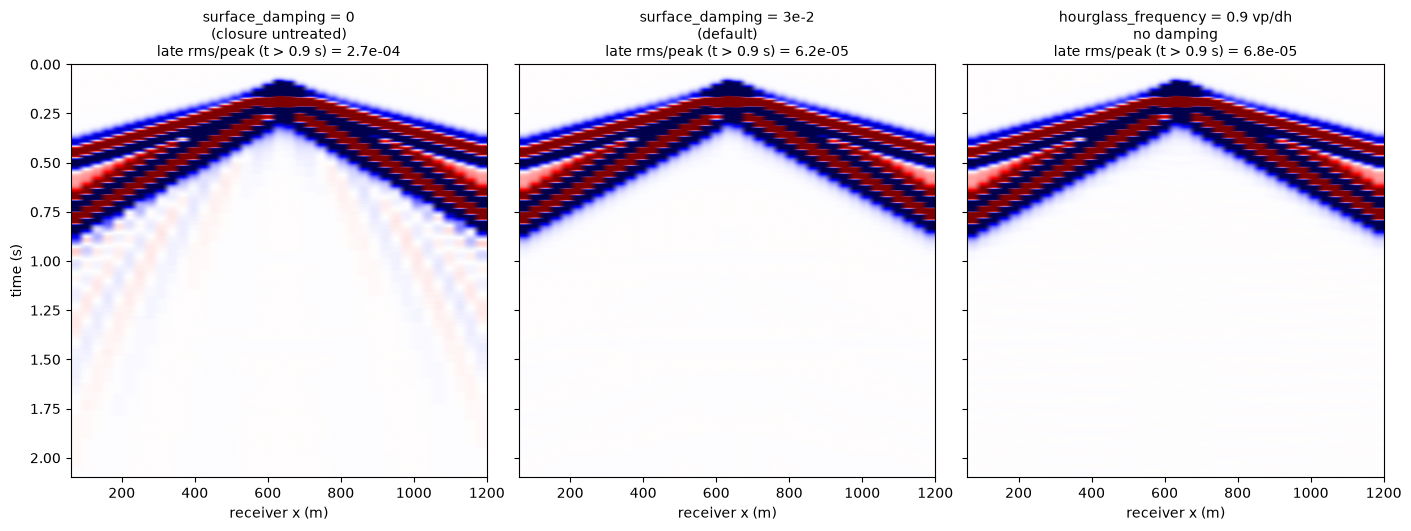

In [6]:
SO_KNOB, NT_KNOB = 16, 4200        # class default order; long enough to see the coda
t_knob = np.arange(NT_KNOB, dtype=np.float32) * DT - DELAY
wavelet_knob = torch.tensor((1.0e3 * ricker(t_knob, f=FREQ)).astype(np.float32)).to(device)

def run_curv_knob(**kw):
    eq = ElasticCurvilinear(spatial_order=SO_KNOB, device=device, backend='torch', **kw)
    prop = PropTorch(eq, shape=(NZ, NX), topography=topo_frac,
                     abcn=ABCN, dh=DH, dt=DT,
                     use_ckpt=False, impl='eager',
                     eager_options={'use_compile': False})
    with torch.no_grad():
        rec = prop(wavelet_knob, sources_curv, receivers_curv, models=[vp, vs, rho])
    return rec[0, :, :, 1].cpu().numpy()

knobs = [
    ('surface_damping = 0\n(closure untreated)',      dict(surface_damping=0.0)),
    ('surface_damping = 3e-2\n(default)',             dict()),
    ('hourglass_frequency = 0.9 vp/dh\nno damping',   dict(surface_damping=0.0,
                                                          hourglass_frequency=0.9 * VP / DH)),
]

t_axis = np.arange(NT_KNOB) * DT
late = t_axis > 0.9                       # everything physical has left the model by then
extent_knob = [rec_x.min() * DH, rec_x.max() * DH, NT_KNOB * DT, 0]

fig, axes = plt.subplots(1, 3, figsize=(14, 5.2), constrained_layout=True, sharey=True)
for ax, (title, kw) in zip(axes, knobs):
    g = run_curv_knob(**kw)
    pk = np.abs(g).max()
    clip = 0.02 * pk                      # same hard clip on all three: gain up the coda
    ax.imshow(g, cmap='seismic', vmin=-clip, vmax=clip,
              extent=extent_knob, aspect='auto')
    rms = np.sqrt((g[late] ** 2).mean()) / pk
    ax.set_title(f'{title}\nlate rms/peak (t > 0.9 s) = {rms:.1e}', fontsize=10)
    ax.set_xlabel('receiver x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

## 4. Wavefield comparison

Running this cell builds a GIF (`15_wavefield_topography.gif`) **next to
the notebook** so the animation works offline / as a standalone asset,
and displays it inline.  Two rows, grouped by physics:

* **Top — Acoustic** *(pressure)*: image · curvilinear
* **Bottom — Elastic** *(|v|)*: image · curvilinear

The air (gray band) is blanked out: the image method leaves its mirrored
ghost values there and they are not part of the solution.  Below the
surface the kinematics match across all methods;
the interesting differences are in the **surface behaviour** —
staircase-corner scattering on the image-method paths and a
geometrically exact flat free surface on the curvilinear paths.  The curvilinear snapshots come
back on the physical (X, Z) grid like the image ones; each panel shares one
colour scale with the others in its row, so amplitudes are directly
comparable across methods, and that scale is recomputed **per frame** (the
running gain is printed in the title) because the P wave leaves this small
model by ~0.5 s while the surface wave is still crossing it.

Saved animation to: 15_wavefield_topography.gif
   size = 3859.6 KB, 29 frames



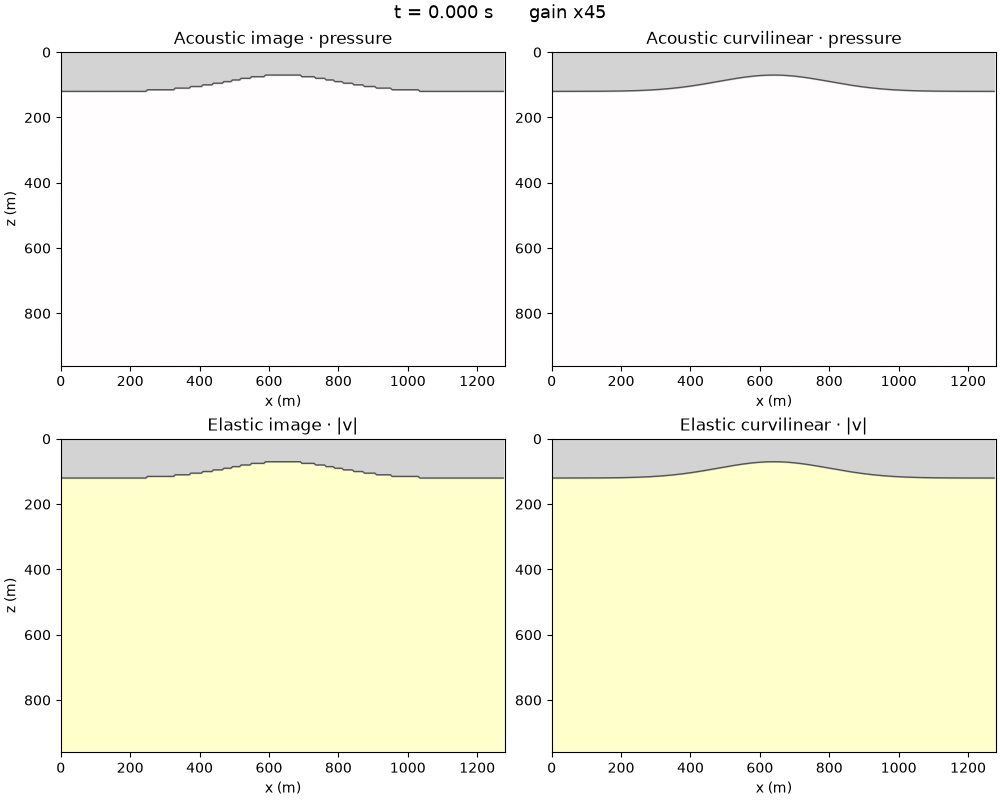

In [7]:
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
from pathlib import Path
from IPython.display import HTML, display

def crop_phys(snap_2d, free_surface):
    """Crop PML padding (top = 0 if free_surface=True, ABCN if =False)."""
    top = 0 if free_surface else ABCN
    return snap_2d[top:top + NZ, ABCN:ABCN + NX]

n_frames = len(snap_idx_ac)

# --- Acoustic (pressure) --------------------------------------------------
p_img  = np.stack([crop_phys(snaps_ac[i, 0, 0, 0].cpu().numpy(), True) for i in range(n_frames)])
p_curv = np.stack([crop_phys(snaps_ac_curv[i, 0, 0, 0].cpu().numpy(), True) for i in range(n_frames)])

# --- Elastic (|v|) --------------------------------------------------------
def vmag(snaps, free_surface):
    vx = np.stack([crop_phys(snaps[i, 0, 0, 0].cpu().numpy(), free_surface) for i in range(n_frames)])
    vz = np.stack([crop_phys(snaps[i, 1, 0, 0].cpu().numpy(), free_surface) for i in range(n_frames)])
    return np.sqrt(vx ** 2 + vz ** 2)

vmag_img  = vmag(snaps_el_img, True)     # image method → top PML suppressed
vmag_curv = vmag(snaps_el_curv, True)

# Blank the air.  The image method leaves its MIRRORED ghost values in the
# cells above the topography -- at t = 0.70 s on this model they peak at
# 1.1e-4 against 5.4e-6 in the real subsurface, i.e. 20x the solution.  They
# are not part of it, so they must not be drawn and must not set the colour
# scale either.  (The curvilinear snapshots are zero there.)
def blank_air(stack):
    out = np.array(stack, dtype=float, copy=True)
    out[:, np.arange(NZ)[:, None] < topo_row[None, :]] = np.nan
    return out

p_img, p_curv = blank_air(p_img), blank_air(p_curv)
vmag_img  = blank_air(vmag_img)
vmag_curv = blank_air(vmag_curv)

# Acoustic: one shared clip for both methods (same amplitude).  This is the
# one place in the notebook that does NOT use the raw signed percentiles:
# most of a snapshot stack is quiet ground and the source lobe is one-signed,
# so percentile(p, [0.5, 99.5]) comes back badly lopsided and puts *zero*
# far off the white point -- the empty half of the model then renders solid
# blue.  A symmetric clip about zero is the readable choice here; the shot
# gathers below, which are two-sided, do use the signed percentiles.
# One clip per ROW, shared by the methods in it, and recomputed PER FRAME:
# the P wave (2200 m/s) leaves this 1.28 x 0.96 km model by ~0.5 s while the
# surface wave is still crossing it, so a single clip for the whole run
# leaves the acoustic panels blank for the second half.  The floor stops the
# gain running away once a row is genuinely empty.
def frame_clips(stacks, pct=99.5, floor=0.02):
    """(n_frames,) colour limit per frame, shared by the given panels."""
    pooled = np.concatenate([np.abs(s) for s in stacks], axis=2)
    per = np.nanpercentile(pooled, pct, axis=(1, 2))
    return np.maximum(per, floor * float(np.nanpercentile(pooled, pct)))

# Acoustic fades out once the P wave has left (nothing to see but PML
# residue); the elastic row keeps a lower floor because its late frames are
# the punchline -- image ringing everywhere, curvilinear clean.
p_clips = frame_clips([p_img, p_curv], floor=0.05)
v_clips = frame_clips([vmag_img, vmag_curv], floor=0.01)

extent = [0, NX * DH, NZ * DH, 0]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)

ims = []
# Row 0 — acoustic pressure
ac_panels = [(axes[0, 0], p_img, 'Acoustic image · pressure'),
             (axes[0, 1], p_curv, 'Acoustic curvilinear · pressure')]
for ax, data, title in ac_panels:
    im = ax.imshow(data[0], cmap='seismic', vmin=-p_clips[0], vmax=p_clips[0],
                   extent=extent, aspect='auto')
    ax.set_title(title); ims.append((im, data, 'p'))
# Row 1 — elastic |v|
el_panels = [(axes[1, 0], vmag_img, 'Elastic image · |v|'),
             (axes[1, 1], vmag_curv, 'Elastic curvilinear · |v|')]
for ax, data, title in el_panels:
    im = ax.imshow(data[0], cmap='YlOrRd', vmin=0, vmax=v_clips[0],
                   extent=extent, aspect='auto')
    ax.set_title(title); ims.append((im, data, 'v'))

# Draw each panel the surface it actually models: the image method sees a
# staircase of whole rows, the curvilinear runs see the smooth hill.
xm = np.arange(NX) * DH
for ax, surf in ((axes[0, 0], topo_row), (axes[0, 1], topo_frac),
                 (axes[1, 0], topo_row), (axes[1, 1], topo_frac)):
    ax.plot(xm, surf * DH, 'k-', lw=1.0, alpha=0.6)
    ax.fill_between(xm, 0, surf * DH, color='lightgray')   # opaque: air is blank
    ax.set_xlabel('x (m)')
axes[0, 0].set_ylabel('z (m)'); axes[1, 0].set_ylabel('z (m)')
title_obj = fig.suptitle(f't = {snap_idx_ac[0] * DT:.3f} s', fontsize=13)

def update(i):
    for im, data, kind in ims:
        im.set_data(data[i])
        im.set_clim(*((-p_clips[i], p_clips[i]) if kind == 'p' else (0.0, v_clips[i])))
    title_obj.set_text(f't = {snap_idx_ac[i] * DT:.3f} s      '
                       f'gain x{p_clips.max() / p_clips[i]:.0f}')
    return [im for im, _, _ in ims] + [title_obj]

anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=120, blit=False)

gif_path = Path('15_wavefield_topography.gif')
anim.save(gif_path, writer=PillowWriter(fps=8))
plt.close(fig)
import base64
gif_b64 = base64.b64encode(gif_path.read_bytes()).decode('ascii')
print(f'Saved animation to: {gif_path}')
print(f'   size = {gif_path.stat().st_size / 1024:.1f} KB, {n_frames} frames')
# Use a raw <img> tag so the GIF renders consistently in Jupyter,
# VSCode, mkdocs-jupyter, and nbviewer — Image() emits a text/plain
# fallback which some renderers prefer over image/gif.
display(HTML(f'<img src="data:image/gif;base64,{gif_b64}" '
             f'alt="topography wavefield animation" '
             f'style="max-width:100%;height:auto;" />'))

## 5. Shot-gather comparison

All methods share the same source / receiver geometry on the irregular
surface, in physical grid indices (the image method rounds the depths to
whole rows, the curvilinear grid takes them exactly).  The hyperbolic
direct wave + free-surface multiples should align in **time** across
methods; differences in amplitude and surface-wave character reflect how
each scheme imposes the traction-free BC.  Same grouping as the
wavefields:

* **Top — Acoustic** *(pressure)*: image · curvilinear
* **Bottom — Elastic** *(vz)*: image · curvilinear

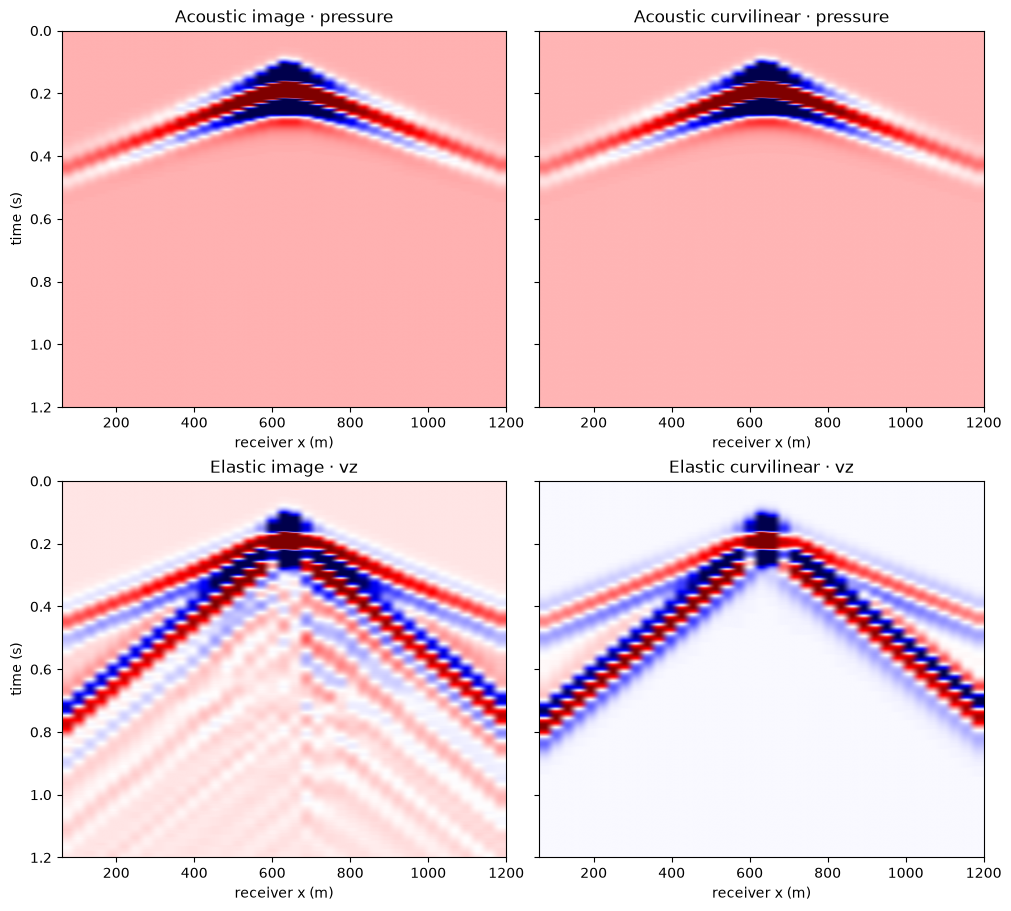

In [8]:
def signed_clip(rec_np, pct=(1.0, 99.0)):
    """Colour limits straight from the raw signed percentiles.

    No ``abs()`` and no forced symmetry: on a shot gather the up- and
    down-going lobes really do differ, and that asymmetry is signal."""
    lo, hi = np.percentile(rec_np, pct)
    return (lo, hi) if hi > lo else (-1e-12, 1e-12)

extent_g = [rec_x.min() * DH, rec_x.max() * DH, NT * DT, 0]

# Acoustic pressure gathers
p_ac_im   = np.squeeze(rec_ac.cpu().numpy())        # (nt, nrec)
p_ac_cv   = np.squeeze(rec_ac_curv.cpu().numpy())
# Elastic vz gathers
vz_el_im  = rec_el_img[0, :, :, 1].cpu().numpy()
vz_el_cv  = rec_el_curv[0, :, :, 1].cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True, sharey=True)

panels = [
    (axes[0, 0], p_ac_im, 'Acoustic image · pressure'),
    (axes[0, 1], p_ac_cv, 'Acoustic curvilinear · pressure'),
    (axes[1, 0], vz_el_im, 'Elastic image · vz'),
    (axes[1, 1], vz_el_cv, 'Elastic curvilinear · vz'),
]
for ax, panel, title in panels:
    lo, hi = signed_clip(panel)
    ax.imshow(panel, cmap='seismic', vmin=lo, vmax=hi,
              extent=extent_g, aspect='auto')
    ax.set_title(title); ax.set_xlabel('receiver x (m)')
axes[0, 0].set_ylabel('time (s)'); axes[1, 0].set_ylabel('time (s)')
plt.show()

## References

1. Mittet, R. (2002). Free-surface boundary conditions for elastic staggered-grid modeling schemes. *Geophysics, 67*(5), 1616–1623. [doi:10.1190/1.1512752](https://doi.org/10.1190/1.1512752) — the vacuum-cell / staircase free-surface scheme used by `Acoustic + topography=`.
2. Robertsson, J. O. A. (1996). A numerical free-surface condition for elastic/viscoelastic finite-difference modeling in the presence of topography. *Geophysics, 61*(6), 1921–1934. [doi:10.1190/1.1444107](https://doi.org/10.1190/1.1444107) — the odd-parity stress-mirror used by `Elastic + topography=`.
3. Bartana, A., Xu, J., & Rickett, J. (2026). Solving the elastodynamic equations in curvilinear coordinates using asymmetric operators. *IMAGE 2026*, expanded abstract (no DOI yet) — the collocated conservative scheme, asymmetric operators and rotated traction-free surface used by `ElasticCurvilinear`.


## Summary · API cheatsheet

```python
from sweep.equations import (
    Acoustic, Elastic,
    AcousticCurvilinear, ElasticCurvilinear,  # boundary-fitted, eager-only
)
from sweep.propagator.torch import PropTorch

# `topo` is the surface row per physical column — shape (nx,), int.
# Only single-valued surfaces: overhangs / caves are not supported
# (a 2-D array raises ValueError).

# --- Acoustic (2 methods) ------------------------------------------------
# image / staircase + vacuum (Mittet 2002) — only physical-grid method
PropTorch(Acoustic(...), topography=topo, ...)
# curvilinear — boundary-fitted grid; physical src/rec, mapped onto its rows
PropTorch(AcousticCurvilinear(...), topography=topo, impl='eager', ...)

# --- Elastic (2 methods) -------------------------------------------------
# Robertsson image method — the physical-grid method
PropTorch(Elastic(...), topography=topo, ...)
# curvilinear — boundary-fitted grid, collocated + asymmetric operators
PropTorch(ElasticCurvilinear(...), topography=topo, impl='eager', ...)

# ElasticCurvilinear free-surface knobs (section 3c)
ElasticCurvilinear(
    spatial_order=16,        # 2L; the paper's L = 8.  Almost free on the
                             # eager path (so=4 -> 20 costs ~8% wall clock)
    surface_damping=3e-2,    # Kreiss-Oliger filter over the surface band.
                             # Dimensionless; 1e-2 ... 1e-1 all work; leave it on
    hourglass_frequency=0.0, # energy-conserving alternative, off by default.
                             # ~0.9*vp/dh, halves dt, needs >=25 pts/wavelength
)
```

Pass `models=[vp]` for the acoustic equations and `models=[vp, vs, rho]`
for the elastic equations.  **Geometry note:** every method takes physical source/receiver
indices (rows of DH from the top, tracking the hill); the curvilinear
propagator maps them onto its boundary-fitted rows itself, fractional
rows included, and its snapshots back onto the physical grid (zero in the
air; `snapshot_grid='computational'` returns the grid's own rows).  Models
are physical-grid models for every method too: the curvilinear propagator
samples each column at the depth of its rows, differentiably, so the
gradient comes back on the physical grid; the rows above the surface are
not read.

**On the curvilinear closure:** `topography=` may be a **fractional**
row array for `ElasticCurvilinear` — rounding the surface to whole rows
turns it into a staircase that radiates grid-scale energy along the free
surface.  The `.round()` above is only needed by the image method.

**On `free_surface`:** passing `topography=` already turns the free
surface on for *every* method (image, curvilinear) — the propagator
infers it, so `free_surface=True` is optional there.  You only need
`free_surface=True` explicitly for a **flat** free surface with no
topography, e.g. `PropTorch(Acoustic(...), free_surface=True, ...)`.

---

<p><strong>Download this notebook</strong> &mdash; <a href="15_wavefield_topography.ipynb" download><code>15_wavefield_topography.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/15_wavefield_topography.ipynb">view on GitHub</a></p>